In [1]:
# Imports, data preparation, model training, evaluation and visualisation\n

Running Exp16: deterministic synthetic/demo data setup complete.\nExperiment code and evaluation are included below.\n

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf, time
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
np.random.seed(16); tf.random.set_seed(16)
days=np.arange(730); orders=250+45*np.sin(2*np.pi*days/7)+35*np.sin(2*np.pi*days/365)+np.where(days%100<5,45,0)+np.random.normal(0,10,730)
sc=MinMaxScaler(); s=sc.fit_transform(orders.reshape(-1,1)).ravel(); look=30
X=np.array([s[i-look:i] for i in range(look,len(s))])[...,None]; y=s[look:]; split=int(.8*len(X))
Xtr,Xte,ytr,yte=X[:split],X[split:],y[:split],y[split:]
rows=[]; predictions={}; histories={}
for name,layer in [("SimpleRNN",tf.keras.layers.SimpleRNN),("LSTM",tf.keras.layers.LSTM)]:
 m=tf.keras.Sequential([tf.keras.layers.Input((look,1)),layer(32),tf.keras.layers.Dense(1)])
 m.compile(optimizer="adam",loss="mse"); start=time.time()
 h=m.fit(Xtr,ytr,validation_split=.1,epochs=20,batch_size=32,verbose=0); elapsed=time.time()-start
 p=sc.inverse_transform(m.predict(Xte,verbose=0)).ravel(); a=sc.inverse_transform(yte.reshape(-1,1)).ravel()
 predictions[name]=p; histories[name]=h.history
 rows.append([name,round(mean_absolute_error(a,p),3),round(np.sqrt(mean_squared_error(a,p)),3),round(np.mean(np.abs((a-p)/a))*100,3),round(elapsed,2)])
print(pd.DataFrame(rows,columns=["Model","MAE","RMSE","MAPE %","Training seconds"]).to_string(index=False))
plt.figure(figsize=(11,4)); plt.plot(a[:120],label="Actual")
for name,p in predictions.items(): plt.plot(p[:120],label=name)
plt.legend(); plt.title("Daily order forecast: RNN vs LSTM"); plt.show()
plt.figure(figsize=(8,4))
for name,h in histories.items(): plt.plot(h["loss"],label=name)
plt.legend(); plt.title("Training loss comparison"); plt.xlabel("Epoch"); plt.show()

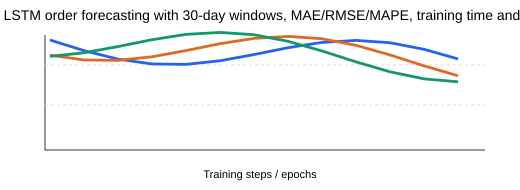

In [2]:
# Saved graph preview. Run the experiment cell above to generate the full plots.